## Setup (Select FRA371_Lab3_env before run this file!)

### Import related libraries/packages

In [21]:
import roboticstoolbox as rtb
import spatialgeometry as sg
from spatialmath import SE3
from swift import Swift
import numpy as np
from pathlib import Path
import roboticstoolbox as rtb
import spatialmath as sm
import matplotlib.pyplot as plt
import time
import matplotlib.ticker as ticker
from Lab3_part_B_utils import *
import math

In [ ]:
'''
*Change this file name to your group number before submission. 
For example, if your group number is 01, change the file name to G01_Lab3_part_B_main.ipynb

Group Number:
Group Members:
1. นิธิโชติ เสนอคำ 67340500024
2. ชนัยชนม์ ฉันทวรกุลชัย 67340500051
3. ศุจิพรรณ ไกรญาณสม 67340500079
'''

'\n*Change this file name to your group number before submission. \nFor example, if your group number is 01, change the file name to G01_Lab3_part_B_main.ipynb\n\nGroup Number:\nGroup Members:\n1.     \n2.\n3.\n'

## Related Function
This lab can be completed by using this function

In [ ]:
# Robotics Toolbox
''' 
robot.jacob0(q)                             : compute eff jacobian
robot.fkine(q)                              : compute forward kinematics
robot.manipulability(q, axes="trans")       : compute (translation) manipalability *Do not forget "axes="trans""!
'''
# Numpy
''' 
np.linalg.eig(M)                       : compute eigen value and eigen vector of matrix M
M @ N                                  : matrix multiplication M multiplied by N
np.linalg.pinv(M)                      : matrix M (pseudo)inversion
'''
# This file
''' 
CalcForwardDK()
CalcInverseDK()
CalcManipulability()
ResolvedRateController()
'''


' \nCalcForwardDK()\nCalcInverseDK()\nCalcManipulability()\nResolvedRateController()\n'

## Robot Preparation*

In [22]:
urdf_file_name = 'robot.urdf'  # Change this to the desired URDF file
robot = DefindeRobot(urdf_file_name=urdf_file_name)  
print(robot)

ERobot: robot, 3 joints (RPP), geometry, collision
┌──────┬───────────────┬───────┬───────────┬─────────────────────────────────────────┐
│ link │     link      │ joint │  parent   │           ETS: parent to link           │
├──────┼───────────────┼───────┼───────────┼─────────────────────────────────────────┤
│    0 │ base_link     │       │ BASE      │ SE3()                                   │
│    1 │ link1         │     0 │ base_link │ SE3(0, 0, 0.01) ⊕ Rz(q0)                │
│    2 │ link2         │     1 │ link1     │ SE3(0, 0, 0.065) ⊕ tz(q1)               │
│    3 │ link3         │     2 │ link2     │ SE3(0, -0.05, 0; 90°, -0°, 0°) ⊕ tz(q2) │
│    4 │ @End Effector │       │ link3     │ SE3(0, 0, 0.155)                        │
└──────┴───────────────┴───────┴───────────┴─────────────────────────────────────────┘



# Part B1: use your robot

### FDK* (Complete the function below)

In [ ]:
def CalcForwardDK(robot: ERobot, q_current: np.ndarray, q_dot: np.ndarray)-> tuple[np.ndarray, np.ndarray]:
    """
    Calculate the forward differential kinematics for a given robot configuration.

    Parameters:
    - robot: The robot object (instance of Robot class).
    - q_current: Current joint angles (numpy array).
    - q_dot: Joint velocities (numpy array).

    Returns:
    - v: Linear velocity of the end-effector (numpy array).
    - omega: Angular velocity of the end-effector (numpy array).
    """
    J0 = robot.jacob0(q_current)
    twist = J0@ q_dot;
    print(twist)
    
    v = np.array([twist[0],twist[1],twist[2]])
    omega = np.array([twist[3],twist[4],twist[5]])

    return v, omega

### Check your A.3 answer*

In [24]:
q           =np.array([np.deg2rad(30), 0, 0])            # edit here
q_dot       =np.array([0.1, 0.1, 0.1])      # edit here
# Hand calculated values in part A item 3 of the assignment
part_A_Vee  =np.array([0.07, -0.08, 0.1])            # edit here

v, omega = CalcForwardDK(robot=robot,
                      q_current=q,
                      q_dot=q_dot) 

error = part_A_Vee - v
print("hand calculated Vee: ", np.round(part_A_Vee, 3))
print("rbt Vee: ", np.round(v, 3))
print("error: ", np.round(error, 3))
if np.all(np.abs(error) < 0.01):
    print("\033[32mpass\033[0m")   # green
else:
    print("\033[31mfail\033[0m")   # red

[[ 1.77535208e-01  0.00000000e+00  5.00000000e-01]
 [ 1.02500000e-01  0.00000000e+00 -8.66025404e-01]
 [ 0.00000000e+00  1.00000000e+00  4.89658886e-12]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 1.00000000e+00  0.00000000e+00  0.00000000e+00]]
[ 0.06775352 -0.07635254  0.1         0.          0.          0.1       ]
hand calculated Vee:  [ 0.07 -0.08  0.1 ]
rbt Vee:  [ 0.068 -0.076  0.1  ]
error:  [ 0.002 -0.004 -0.   ]
pass


### IDK* (Complete the function below)

In [33]:
def CalcInverseDK(robot, q_current, v_desired):
    """
    Calculate the inverse differential kinematics for a given robot configuration.

    Parameters:
    - robot: The robot object (instance of Robot class).
    - q_current: Current joint angles (numpy array).
    - v_desired: Desired linear velocity of the end-effector (numpy array).

    Returns:
    - q_dot: Joint velocities required to achieve the desired end-effector velocities (numpy array).
    """
    J0 = robot.jacob0(q_current)
    Re_J_0 = J0[0:3]
    # print(Re_J_0)
    q_dot = np.linalg.pinv(Re_J_0)@v_desired

    return q_dot

### Check your A.4 answer*

In [36]:
q_current   =np.array([np.deg2rad(30), 0, 0])    # edit here
v_desired   =np.array([0.1, 0.1, 0])    # edit here
# Hand calculated values in part A item 4 of the assignment
part_A_q_dot  =np.array([0.66, 0, -0.04,]) # edit here

q_dot = CalcInverseDK(robot=robot,
                      q_current=q_current,
                      v_desired=v_desired)

error = part_A_q_dot - q_dot
print("hand calculated q_dot: ", np.round(part_A_q_dot, 3))
print("rbt q_dot: ", np.round(q_dot, 3))
print("error: ", np.round(error, 3))
if np.all(np.abs(error) < 0.01):
    print("\033[32mpass\033[0m")   # green
else:
    print("\033[31mfail\033[0m")   # red

hand calculated q_dot:  [ 0.66  0.   -0.04]
rbt q_dot:  [ 0.666  0.    -0.037]
error:  [-0.006 -0.    -0.003]
pass


### Manipulability* (Complete the function below)

In [49]:
def CalcManipulability(robot, q_current):
    """
    Calculate the manipulability measure for a given robot configuration.

    Parameters:
    - robot: The robot object (instance of Robot class).
    - q_current: Current joint angles (numpy array).

    Returns:
    - manipulability: The translational manipulability measure (float).
    - eigenvalues: The eigenvalues of the Jacobian matrix (numpy array).
    - eigenvectors: The eigenvectors of the Jacobian matrix (numpy array).
    """
    manipulability = robot.manipulability(q_current, axes="trans")
    J0 = robot.jacob0(q_current)
    re_J0 = J0[0:3]
    A = re_J0@np.transpose(re_J0)
    eigenvalues, eigenvectors = np.linalg.eig(A) 

    return manipulability, eigenvalues, eigenvectors

### Check your A.6answer*

In [50]:
q_current   =np.array([0, 0, 0])   # edit here
# Hand calculated value in part A item 6 of the assignment
part_A_manipulability   = 0.21      # edit here

manipulability, eigenvalues, eigenvectors = CalcManipulability(robot=robot,
                                                               q_current=q_current)
error = part_A_manipulability - manipulability
print("hand calculated manipulability: ", np.round(part_A_manipulability, 3))
print("Manipulability: ", np.round(manipulability, 3))
print("error: ", np.round(error, 3))
if np.all(np.abs(error) < 0.01):
    print("\033[32mpass\033[0m")   # green
else:
    print("\033[31mfail\033[0m")   # red
print("Eigenvalues: ", np.round(eigenvalues, 3))
print("Eigenvectors: \n", np.round(eigenvectors, 3))

hand calculated manipulability:  0.21
Manipulability:  0.205
error:  0.005
pass
Eigenvalues:  [1.    1.    0.042]
Eigenvectors: 
 [[ 0.     0.     1.   ]
 [-0.707  0.707  0.   ]
 [ 0.707  0.707  0.   ]]


In [51]:

q_current  = np.array([0,0,0])  
robot.q = q_current  # Set the robot to a specific configuration

env = Swift()
env.launch(realtime=True, browser="notebook")
env.add(robot)


ManipulabilityViz(robot=robot,
                  env=env,
                  eigenvalues=eigenvalues,
                  eigenvectors=eigenvectors,)
print("Current joint angles (radians): ", np.round(robot.q, 3))
print("End-effector position: ", np.round(robot.fkine(robot.q).t, 3))

Vector Cyan = Eigenvalue 0: 1.0
Vector Magenta = Eigenvalue 1: 1.0
Vector Yellow = Eigenvalue 2: 0.042
Current joint angles (radians):  [0. 0. 0.]
End-effector position:  [ 0.    -0.205  0.075]


# Part B2: use Dummy robot

### Resolved-Rate Controller* (Complete the function below)

In [91]:
def ResolvedRateController(robot, q_current, P_desired):
    """
    Perform resolved rate control for a given robot configuration.

    Parameters:
    - robot: The robot object (instance of Robot class).
    - q_current: Current joint angles (numpy array).
    - P_desired: Desired position of the end-effector (numpy array).

    Returns:
    - q_dot: Required joint velocities (numpy array).
    """
    Kp = 5  # Proportional gain (tune this value as needed)
    P_e = robot.fkine(q_current).t
    error = P_desired - P_e
    
    v_desired = Kp*error

    q_dot  = CalcInverseDK(robot=robot,
                      q_current=q_current,
                      v_desired=v_desired)

    return q_dot, error


### Simulation loop* (Complete the code below)

In [92]:
total_time = 10.0   # [s]
current_time = 0.0  # [s]
dt = 0.01 # [s]

# Set initial pose here.
urdf_file_name = 'Dummy_articulated_RRR.urdf'  # Change this to the desired URDF file
robot = DefindeRobot(urdf_file_name=urdf_file_name)  
env2 = SetupSimulation(robot=robot, start_position=[0.6, -0.4, 0.4])

box = sg.Cuboid(
    scale=[0.1, 0.1, 0.1], 
    pose=sm.SE3(0.6, -0.3, 0.4),
    color=[0.65, 0.65, 0.65, 1.0]     # RGBA color format (Gray, solid)
)
env2.add(box)

M_hist = []
q_dot_hist = []
err_hist = []
timestamp = []

while current_time < total_time:
    current_box_position = sm.SE3(box.T).t
    q_current = robot.q
    #===============================================================================================================
    # Add your code inside this area.

    manipulability, eigenvalues, eigenvectors = CalcManipulability(robot=robot,
                                                               q_current=q_current)     # Call the CalcManipulability function to get manipulability, eigenvalues, and eigenvectors
    q_dot,err = ResolvedRateController(robot=robot,q_current=q_current,P_desired=current_box_position)                                    # Call the ResolvedRateController function to get q_dot and err

    #===============================================================================================================
    robot.qd = q_dot
    if current_time < 4.0:
        V=np.array([0.05, 0.06, 0.02])
    elif 0.4<= current_time < 8.0:
        V=np.array([-0.02, -0.03, -0.01])
    else:
        V=np.array([0.0, 0.0, 0.03])
    UpdateBoxPosition(box=box, P_current=current_box_position, V=V, dt=dt)
    M_hist.append(manipulability)
    q_dot_hist.append(q_dot)
    err_hist.append(err)
    env2.step(dt)
    timestamp.append(current_time)
    current_time += dt
    
q_dot_hist = np.array(q_dot_hist)
M_hist = np.array(M_hist)
err_hist = np.array(err_hist)
timestamp = np.array(timestamp)

### Plot

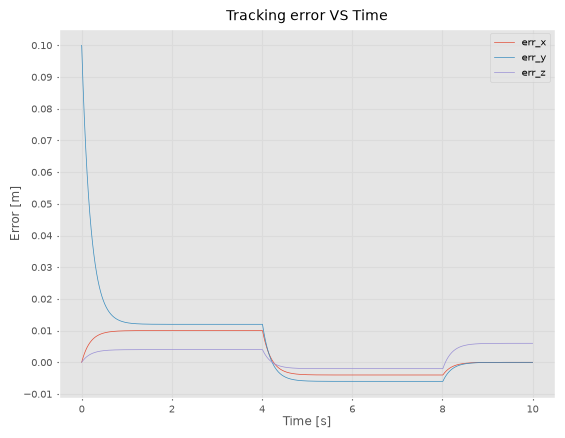

In [93]:
PlotTrackingError(timestamp=timestamp, err_hist=err_hist)

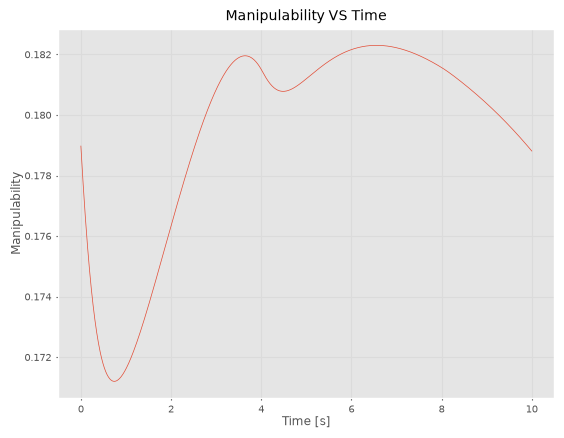

In [82]:
PlotManipulability(timestamp=timestamp, M_hist=M_hist)

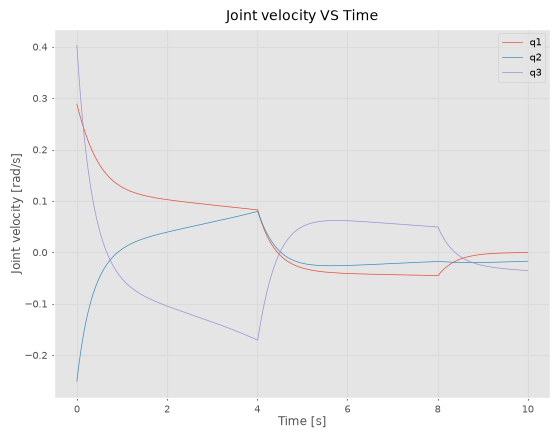

In [83]:
PlotJointVelocity(timestamp=timestamp, q_dot_hist=q_dot_hist)

# Part B3 Singularlity Inspection: use Dummy robot

### Simulation loop* (Complete the code below)

In [103]:
total_time = 8.0   # [s]
current_time = 0.0  # [s]
dt = 0.01 # [s]

env3 = SetupSimulation(robot=robot, start_position=[0.6, 0.0, 0.2])

M_hist = []
q_dot_hist = []
eigval_hist = []
eigvec_hist = []
timestamp = []

while current_time < total_time:
    q_current = robot.q
    #===============================================================================================================
    # Add your code inside this area.

    manipulability, eigenvalues, eigenvectors = CalcManipulability(robot=robot,
                                                               q_current=q_current)     # Call the CalcManipulability function to get manipulability, eigenvalues, and eigenvectors
    q_dot =  CalcInverseDK(robot=robot,
                      q_current=q_current,
                      v_desired=np.array([0.1, 0.0, 0.0]))
                                       # Call the CalcInverseDK function to get q_dot (v_desired = np.array([0.1, 0.0, 0.0]))
    robot.qd = q_dot
    #===============================================================================================================
    M_hist.append(manipulability)
    q_dot_hist.append(q_dot)
    eigval_hist.append(eigenvalues)
    eigvec_hist.append(eigenvectors)
    timestamp.append(current_time)
    env3.step(dt)
    current_time += dt
    
q_dot_hist = np.array(q_dot_hist)
M_hist = np.array(M_hist)
timestamp = np.array(timestamp)

### Plot

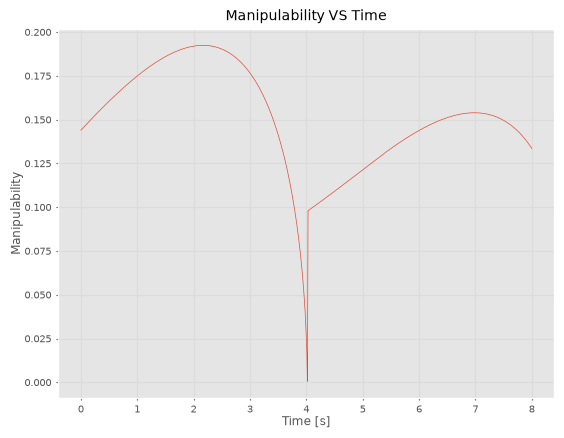

In [104]:
PlotManipulability(timestamp=timestamp, M_hist=M_hist)

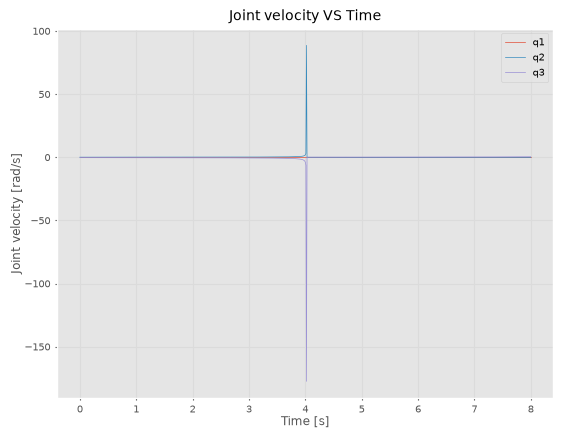

In [105]:
PlotJointVelocity(timestamp=timestamp, q_dot_hist=q_dot_hist)

### Answer area for question B3*

จากกราฟเเสดงให้เห็นว่า ณ จุดที่ Manipulability เข้าใกล้ 0 ขนาดของความเร็วจะมีขนาดมาก